# 2. Análise exploratória: Bike Sharing

**Objetivo:** entender os dados antes de modelar e, principalmente, **descobrir que tipo de drift existe entre 2011 e 2012**, para saber o que esperar do whylogs.

Perguntas:
1. Como é a distribuição de `cnt`?
2. O uso mudou entre 2011 e 2012? Quem mudou: usuários avulsos ou cadastrados?
3. O que mais explica o uso (hora, dia útil, clima)?
4. As **features** mudaram entre os anos, ou só o **target**?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp, chi2_contingency

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"
YEAR_COLORS = {2011: BLUE, 2012: ORANGE}
sns.set_theme(style="whitegrid", rc={"grid.color": "#e6e5e0", "axes.edgecolor": "#c3c2b7"})
pd.set_option("display.max_columns", 50)

df = pd.read_parquet("../data/processed/bike_clean.parquet")
print(df.shape)

(17379, 17)


## 1. Distribuição de `cnt`

assimetria original: 1.28
assimetria com log : -0.82


count    17379.0
mean       189.5
std        181.4
min          1.0
25%         40.0
50%        142.0
75%        281.0
max        977.0
Name: cnt, dtype: float64

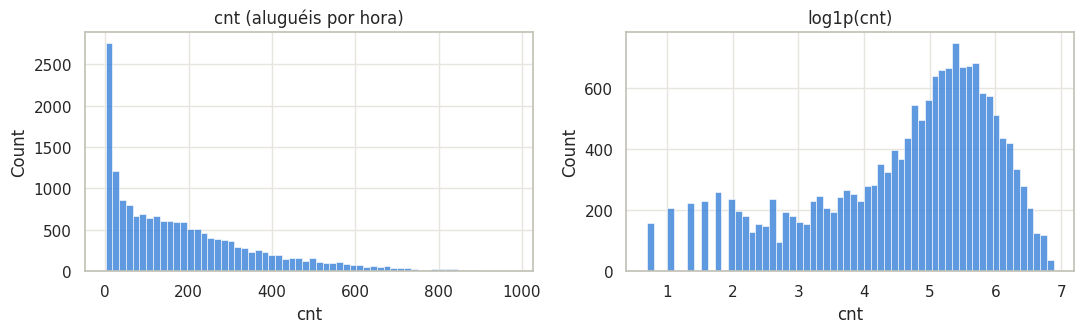

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df["cnt"], bins=60, ax=ax[0], color=BLUE).set_title("cnt (aluguéis por hora)")
sns.histplot(np.log1p(df["cnt"]), bins=60, ax=ax[1], color=BLUE).set_title("log1p(cnt)")
plt.tight_layout()

print("assimetria original:", round(df["cnt"].skew(), 2))
print("assimetria com log :", round(np.log1p(df["cnt"]).skew(), 2))
df["cnt"].describe().round(1)

`cnt` é uma **contagem** muito assimétrica: muitas horas de madrugada com poucos aluguéis e picos de quase 1.000 nos horários de pico. O log deixa a distribuição bem mais comportada, então vamos treinar em `log1p(cnt)` com correção de viés na volta, como no projeto do Ames.

> Atenção: no log a assimetria fica **negativa** (cauda à esquerda, das madrugadas). Isso é esperado para contagens com muitos valores pequenos.

## 2. O uso mudou entre 2011 e 2012?

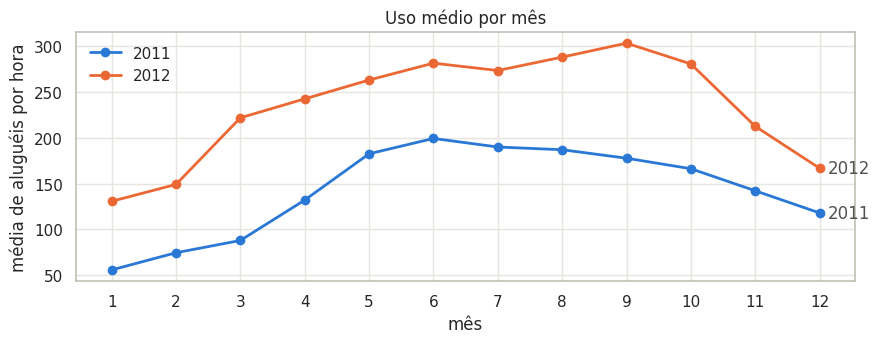

2012 / 2011 por mês: {1: 2.35, 2: 2.01, 3: 2.53, 4: 1.84, 5: 1.44, 6: 1.41, 7: 1.44, 8: 1.54, 9: 1.71, 10: 1.69, 11: 1.5, 12: 1.41}
média geral 2011: 143.8 | 2012: 234.7


In [3]:
mensal = df.groupby(["year", "month"])["cnt"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(9, 3.6))
for y in [2011, 2012]:
    ax.plot(mensal.index, mensal[y], marker="o", lw=2, ms=6, color=YEAR_COLORS[y], label=str(y))
    ax.annotate(str(y), (12, mensal.loc[12, y]), xytext=(6, 0), textcoords="offset points",
                color=GRAY, va="center")
ax.set_xticks(range(1, 13))
ax.set_xlabel("mês"); ax.set_ylabel("média de aluguéis por hora")
ax.set_title("Uso médio por mês")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

ratio = (mensal[2012] / mensal[2011]).round(2)
print("2012 / 2011 por mês:", ratio.to_dict())
print("média geral 2011:", round(df.loc[df.year == 2011, "cnt"].mean(), 1),
      "| 2012:", round(df.loc[df.year == 2012, "cnt"].mean(), 1))

O formato sazonal é o mesmo nos dois anos (pico no verão, vale no inverno), mas **2012 está em outro patamar**: em todos os meses o uso é de 1,4× a 2,5× maior que no mesmo mês de 2011. É crescimento do sistema, não mudança de clima.

In [4]:
by_user = df.groupby("year")[["casual", "registered"]].sum()
share = by_user.div(by_user.sum(axis=1), axis=0).round(3)
growth = (by_user.loc[2012] / by_user.loc[2011] - 1).round(3)

display(by_user.assign(total=by_user.sum(axis=1)))
print("crescimento 2011 → 2012:", growth.to_dict())
print("participação dos cadastrados:", share["registered"].to_dict())

,casual,registered,total
year,,,
2011,247252,995851,1243103
2012,372765,1676811,2049576


crescimento 2011 → 2012: {'casual': 0.508, 'registered': 0.684}
participação dos cadastrados: {2011: 0.801, 2012: 0.818}


Os dois tipos de usuário crescem, e os **cadastrados** respondem pela maior parte dos aluguéis e do crescimento. Como nenhuma feature do modelo mede "tamanho da base de usuários", um modelo treinado em 2011 **não tem como saber** desse crescimento.

## 3. O que explica o uso?

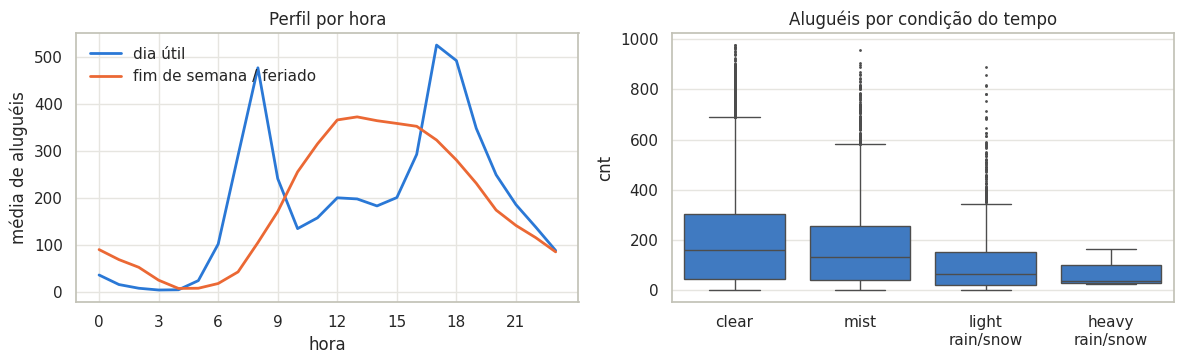

In [5]:
perfil = df.groupby(["workingday", "hour"])["cnt"].mean().unstack(0)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(perfil.index, perfil[1], lw=2, color=BLUE, label="dia útil")
ax[0].plot(perfil.index, perfil[0], lw=2, color=ORANGE, label="fim de semana / feriado")
ax[0].set_xticks(range(0, 24, 3)); ax[0].set_xlabel("hora"); ax[0].set_ylabel("média de aluguéis")
ax[0].set_title("Perfil por hora"); ax[0].legend(frameon=False)

order = ["clear", "mist", "light_rain_snow", "heavy_rain_snow"]
sns.boxplot(data=df, x="weather", y="cnt", order=order, ax=ax[1], color=BLUE, fliersize=1)
ax[1].set_title("Aluguéis por condição do tempo"); ax[1].set_xlabel("")
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(["clear", "mist", "light\nrain/snow", "heavy\nrain/snow"])
plt.tight_layout(); plt.show()

- **Hora + tipo de dia** é o padrão dominante: em dia útil há dois picos (8h e 17–18h, trajeto casa–trabalho); no fim de semana, uma curva única à tarde (lazer).
- **Chuva** derruba o uso; a categoria `heavy_rain_snow` quase não tem amostras.

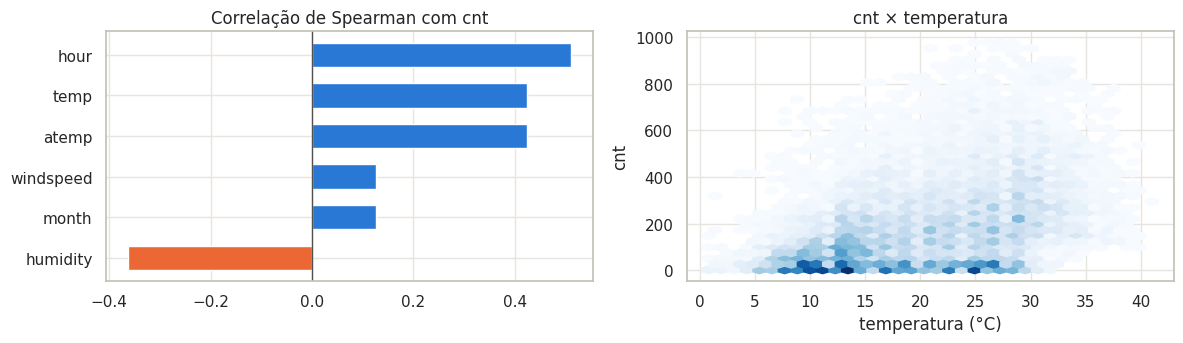

In [6]:
num = ["temp", "atemp", "humidity", "windspeed", "hour", "month"]
corr = df[num + ["cnt"]].corr(method="spearman")["cnt"].drop("cnt").sort_values()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].barh(corr.index, corr.values, color=[BLUE if v > 0 else ORANGE for v in corr.values], height=0.6)
ax[0].axvline(0, color=GRAY, lw=1); ax[0].set_title("Correlação de Spearman com cnt")
ax[1].hexbin(df["temp"], df["cnt"], gridsize=35, cmap="Blues", mincnt=1)
ax[1].set_xlabel("temperatura (°C)"); ax[1].set_ylabel("cnt"); ax[1].set_title("cnt × temperatura")
plt.tight_layout(); plt.show()

`atemp` e `temp` são quase a mesma variável (sensação térmica × temperatura). Manteremos as duas, porque árvores lidam bem com colinearidade, mas vale lembrar dela ao ler os relatórios.

## 4. Mudaram as features ou só o target?

Comparamos 2011 e 2012 coluna a coluna: **KS** para numéricas e **Cramér's V** para categóricas, os mesmos testes que o whylogs usa por padrão no relatório de drift.

In [7]:
def cramers_v(a, b):
    tab = pd.crosstab(np.r_[np.zeros(len(a)), np.ones(len(b))], np.r_[a, b])
    chi2 = chi2_contingency(tab)[0]
    n = tab.values.sum()
    return np.sqrt(chi2 / (n * (min(tab.shape) - 1)))

a, b = df[df.year == 2011], df[df.year == 2012]
rows = []
for c in ["temp", "atemp", "humidity", "windspeed", "hour", "month"]:
    rows.append((c, "KS", ks_2samp(a[c].dropna(), b[c].dropna()).statistic))
for c in ["season", "weather", "weekday", "holiday", "workingday"]:
    rows.append((c, "Cramér's V", cramers_v(a[c].astype(str), b[c].astype(str))))
for c in ["cnt", "registered", "casual"]:
    rows.append((c + "  ← target/derivadas", "KS", ks_2samp(a[c], b[c]).statistic))

drift = pd.DataFrame(rows, columns=["coluna", "métrica", "score"]).set_index("coluna").round(3)
drift.sort_values("score", ascending=False)

,métrica,score
coluna,,
registered ← target/derivadas,KS,0.227
cnt ← target/derivadas,KS,0.216
casual ← target/derivadas,KS,0.117
humidity,KS,0.066
temp,KS,0.055
atemp,KS,0.046
weather,Cramér's V,0.032
windspeed,KS,0.019
season,Cramér's V,0.012


**Conclusão principal da EDA:** as features praticamente não mudam entre os anos (scores perto de zero; o clima de 2012 é parecido com o de 2011), mas o **target muda bastante** (`cnt` e principalmente `registered`).

Isso é ***concept drift***: a relação entre clima/calendário e uso mudou, porque o sistema cresceu. Consequências para o projeto:
- Uma medida de drift das features baseada no **tamanho** da diferença **não vai acusar nada**; testes baseados em **p-valor** podem acusar mesmo assim, só porque as amostras são grandes;
- Quem precisa acusar o problema é o **target** (`cnt`, quando o valor real chega) e as **métricas de desempenho** do modelo (RMSE e viés);
- O modelo treinado em 2011 deve **subestimar** 2012 de forma sistemática.

Por isso o `modelling.ipynb` treina **somente com 2011**, e 2012 fica inteiro como "produção".